# P5 Encoding — EDA trên snapshot ứng viên

Snapshot R2 P4 đã tải, chưa được Phát duyệt sử dụng chính thức. Notebook kiểm tra bytes từ manifest trước mọi thống kê. Không sửa input, không xuất production, không dùng model/LLM hoặc dịch JD. Kết quả chỉ mô tả snapshot này, không đại diện toàn thị trường Việt Nam.

**Job coverage** = jobs có ≥1 giá trị trong vocabulary / tổng jobs. **Pair coverage** = cặp job–skill giữ lại / toàn bộ cặp trên cùng biểu diễn. **Sparsity** = số ô 0 / tổng ô. Raw values không đồng nghĩa kỹ năng chuẩn.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
from collections import Counter
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = Path.cwd()
if not (ROOT/'preprocessing').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from preprocessing.encoding.skills_taxonomy_230 import TAXONOMY_230, SKILL_LOOKUP_MAP, ALIAS_CONFLICTS
from preprocessing.encoding.run import to_col_slug
SNAP=ROOT/'reports/preprocessing/05_encoding/snapshot_audit_2026-11-08'
OUT=ROOT/'reports/preprocessing/05_encoding/review_2026-11-08'
OUT.mkdir(exist_ok=True)
manifest=json.loads((SNAP/'manifest.json').read_text())
frames=[]; schema={}
for item in manifest:
    src=item['key'].split('/')[1]; p=SNAP/f'{src}.parquet'
    assert hashlib.sha256(p.read_bytes()).hexdigest()==item['sha256']
    table=pq.read_table(p); d=table.to_pandas()
    assert len(d)==item['rows'] and set(d.source_platform)=={src}
    assert d.job_id_global.notna().all() and d.job_id_global.is_unique
    frames.append(d); schema[src]={f.name:(str(f.type),f.nullable) for f in table.schema}
assert len(frames)==8
df=pd.concat(frames,ignore_index=True)
assert df.job_id_global.notna().all() and df.job_id_global.is_unique
print('Environment:',platform.python_version(),'pandas',pd.__version__,'numpy',np.__version__)
print('Shape:',df.shape,'Snapshot generated-at:',{m['metadata']['generated-at'] for m in manifest})
display(pd.DataFrame([{k:v for k,v in m.items() if k!='schema'} for m in manifest]))


Environment: 3.14.4 pandas 3.1.1 numpy 2.5.4
Shape: (5177, 62) Snapshot generated-at: {'2026-11-03T17:13:07+00:00'}


,key,etag,sha256,bytes,rows,metadata
0,staging/topcv/preprocessing/04_normalization.p...,"""66e1221b2a817cc456d31b47e9455934""",90fca2f0d34462e7eb36992e4ec8af369882010c01d29e...,4147347,1561,"{'step': '04_normalization', 'rows': '1561', '..."
1,staging/topdev/preprocessing/04_normalization....,"""ec275a1719321bd6831155f786372113""",867d8b73650a7f218128e014acd264fdac5fccf73584aa...,724907,227,"{'step': '04_normalization', 'rows': '227', 'g..."
2,staging/vietnamworks/preprocessing/04_normaliz...,"""e2805f0d0ecc8e9dd679e6f07efc0825""",76a19016863b26ae2f0608d310a297c42a664d25910872...,2443352,900,"{'step': '04_normalization', 'rows': '900', 'g..."
3,staging/careerviet/preprocessing/04_normalizat...,"""9363aa9a8cbed9bdb5b37dad5f7ec401""",5f974ebf826dcf92a02732ccd06f743f296c13acd7a340...,1513977,448,"{'step': '04_normalization', 'rows': '448', 'g..."
4,staging/vieclam24h/preprocessing/04_normalizat...,"""c1f54debb95fe229e6dfaad9920a0dd7""",3abc6d36365202ddcb669b21ac9597fbe5cf0ffee0e751...,499603,182,"{'step': '04_normalization', 'rows': '182', 'g..."
5,staging/itviec/preprocessing/04_normalization....,"""4ab4944d0e000ecb8d6a63004712dfde""",bec7ca1f74bdaf2c3f53dd7841b8659f4ff86104fe22de...,3255647,905,"{'step': '04_normalization', 'rows': '905', 'g..."
6,staging/glints/preprocessing/04_normalization....,"""418f16f3960baae7197c66bf8be8cafe""",cefc0dc0f081c3f9e17be8218ecee9d8975b6a2136aa1b...,934186,271,"{'step': '04_normalization', 'rows': '271', 'g..."
7,staging/jobsgo/preprocessing/04_normalization....,"""8ce531da89c9cec466ea4f6560afb405""",9fbff92fbe8ec4a8f81a2aae7f7a4460ed153cfa327ea8...,1342142,683,"{'step': '04_normalization', 'rows': '683', 'g..."


## Schema, input contract và anomalies
Không ép kiểu. Null-only Arrow type có thể hợp nhất trên bản phân tích nhưng chưa phải quyết định schema giao nhận.

In [2]:
diff=[]
for field in sorted(set().union(*(s.keys() for s in schema.values()))):
    types={src:str(s.get(field,('ABSENT',None))) for src,s in schema.items()}
    if len(set(types.values()))>1:
        physical={s.get(field,('ABSENT',None))[0] for s in schema.values()}
        nullonly=(('null' in physical and len(physical-{'null'})==1) or ('list<element: null>' in physical and physical <= {'list<element: null>','list<element: string>'}))
        diff.append(dict(field=field,**types,difference='null-only' if nullonly else 'type/nullable mismatch',impact='no observed encoding failure; review Arrow join' if nullonly else 'check semantics before conversion',proposal='nullable counterpart on analysis copy only' if nullonly else 'inspect per-source type; no coercion',phat_review='yes for official schema'))
schema_diff=pd.DataFrame(diff); schema_diff.to_csv(OUT/'schema_diff.csv',index=False)
display(schema_diff)
display(pd.DataFrame({'null_jobs':df.isna().sum(),'null_rate':df.isna().mean()}))
for field,kind in [('skills_std',str),('locations',dict)]:
    assert df[field].apply(lambda a:isinstance(a,(list,tuple,np.ndarray)) and all(isinstance(v,kind) for v in a)).all()
print('Empty arrays:',{f:int(df[f].apply(len).eq(0).sum()) for f in ['skills_std','locations']})
from preprocessing.encoding.run import encode_dataset
encoded,_,_=encode_dataset(df)
anomalies=[]
for i,r in df.iterrows():
    if r.exp_min_years>r.exp_max_years:
        anomalies.append(dict(job_id_global=r.job_id_global,field='experience_range',value=str((r.exp_min_years,r.exp_max_years)),reason='min > max',derived_effect=str(encoded.loc[i,['exp_min_years','exp_max_years','exp_min_years__missing','exp_max_years__missing']].to_dict())))
    if pd.to_datetime(r.deadline_date,errors='coerce')<pd.to_datetime(r.posted_date,errors='coerce'):
        anomalies.append(dict(job_id_global=r.job_id_global,field='date_range',value=str((r.posted_date,r.deadline_date)),reason='deadline before posting',derived_effect=str(encoded.loc[i,['days_to_deadline','days_to_deadline__missing']].to_dict())))
an=pd.DataFrame(anomalies)
an['evidence']='executed current encoder on checksum-verified P4 snapshot'
an['options']='retain + flag / set derived feature missing; source unchanged'
an['recommendation']='flag for review; Phat decides derived missing policy'
an.to_csv(OUT/'anomalies_review.csv',index=False); display(an)


,field,topcv,topdev,vietnamworks,careerviet,vieclam24h,itviec,glints,jobsgo,difference,impact,proposal,phat_review
0,also_on,"('list<element: string>', True)","('list<element: null>', True)","('list<element: string>', True)","('list<element: string>', True)","('list<element: string>', True)","('list<element: null>', True)","('list<element: null>', True)","('list<element: string>', True)",null-only,no observed encoding failure; review Arrow join,nullable counterpart on analysis copy only,yes for official schema
1,flags,"('list<element: string>', True)","('list<element: null>', True)","('list<element: string>', True)","('list<element: string>', True)","('list<element: string>', True)","('list<element: string>', True)","('list<element: string>', True)","('list<element: string>', True)",null-only,no observed encoding failure; review Arrow join,nullable counterpart on analysis copy only,yes for official schema
2,skills_list,"('list<element: string>', True)","('list<element: string>', True)","('list<element: string>', True)","('null', True)","('list<element: string>', True)","('list<element: string>', True)","('list<element: string>', True)","('null', True)",null-only,no observed encoding failure; review Arrow join,nullable counterpart on analysis copy only,yes for official schema


,null_jobs,null_rate
job_id_global,0,0.000000
source_platform,0,0.000000
source_job_id,0,0.000000
source_url,0,0.000000
crawled_at,0,0.000000
...,...,...
is_outlier_salary,0,0.000000
salary_min_vnd_capped,3115,0.601700
salary_max_vnd_capped,2899,0.559977
log_salary_min,3115,0.601700


Empty arrays: {'skills_std': 412, 'locations': 0}


,job_id_global,field,value,reason,derived_effect,evidence,options,recommendation
0,careerviet_35C880C1,date_range,"('2026-10-13', '2026-10-02')",deadline before posting,"{'days_to_deadline': nan, 'days_to_deadline__m...",executed current encoder on checksum-verified ...,retain + flag / set derived feature missing; s...,flag for review; Phat decides derived missing ...
1,careerviet_35C880C2,date_range,"('2026-10-13', '2026-10-02')",deadline before posting,"{'days_to_deadline': nan, 'days_to_deadline__m...",executed current encoder on checksum-verified ...,retain + flag / set derived feature missing; s...,flag for review; Phat decides derived missing ...
2,careerviet_35C8818A,date_range,"('2026-10-13', '2026-09-25')",deadline before posting,"{'days_to_deadline': nan, 'days_to_deadline__m...",executed current encoder on checksum-verified ...,retain + flag / set derived feature missing; s...,flag for review; Phat decides derived missing ...
3,careerviet_35C882B5,date_range,"('2026-10-13', '2026-10-07')",deadline before posting,"{'days_to_deadline': nan, 'days_to_deadline__m...",executed current encoder on checksum-verified ...,retain + flag / set derived feature missing; s...,flag for review; Phat decides derived missing ...
4,careerviet_35C88876,experience_range,"(5.0, 3.0)",min > max,"{'exp_min_years': 5.0, 'exp_max_years': 3.0, '...",executed current encoder on checksum-verified ...,retain + flag / set derived feature missing; s...,flag for review; Phat decides derived missing ...
5,careerviet_35C88996,date_range,"('2026-11-01', '2026-10-28')",deadline before posting,"{'days_to_deadline': nan, 'days_to_deadline__m...",executed current encoder on checksum-verified ...,retain + flag / set derived feature missing; s...,flag for review; Phat decides derived missing ...
6,careerviet_35C88B4D,date_range,"('2026-10-05', '2026-09-29')",deadline before posting,"{'days_to_deadline': nan, 'days_to_deadline__m...",executed current encoder on checksum-verified ...,retain + flag / set derived feature missing; s...,flag for review; Phat decides derived missing ...
7,careerviet_35C89455,date_range,"('2026-10-15', '2026-10-10')",deadline before posting,"{'days_to_deadline': nan, 'days_to_deadline__m...",executed current encoder on checksum-verified ...,retain + flag / set derived feature missing; s...,flag for review; Phat decides derived missing ...
8,careerviet_35C890B4,date_range,"('2026-10-21', '2026-10-10')",deadline before posting,"{'days_to_deadline': nan, 'days_to_deadline__m...",executed current encoder on checksum-verified ...,retain + flag / set derived feature missing; s...,flag for review; Phat decides derived missing ...


## Skill/job và tần suất
Mỗi giá trị được đếm tối đa một lần trong một job; bao gồm jobs không có skill.

Jobs with any skill: 4765 / 5177


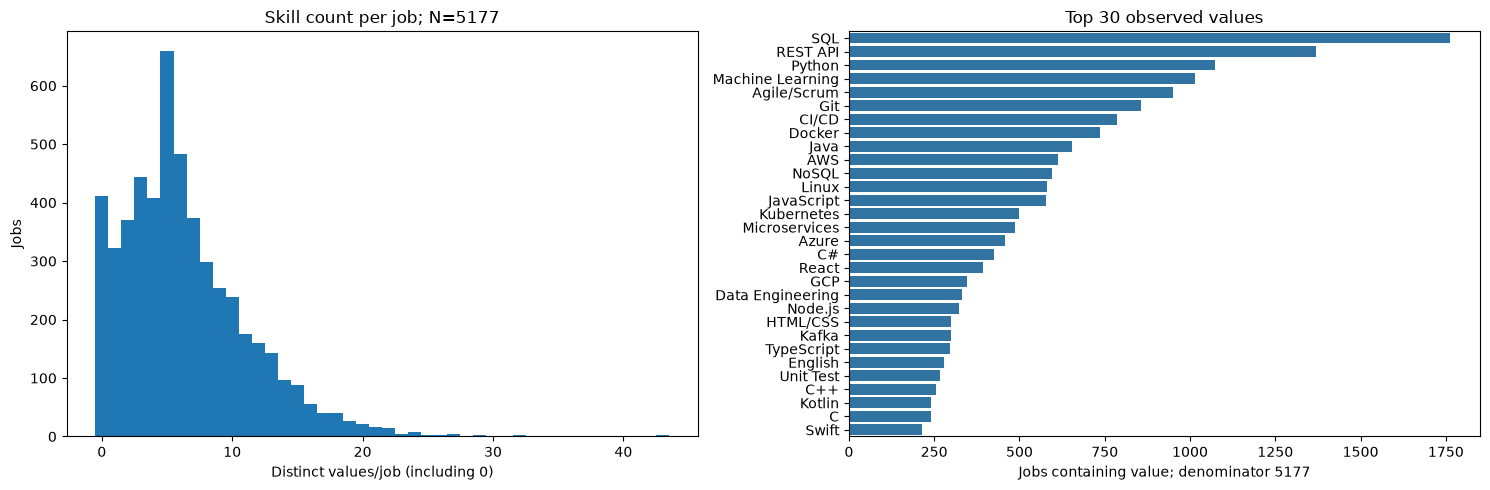

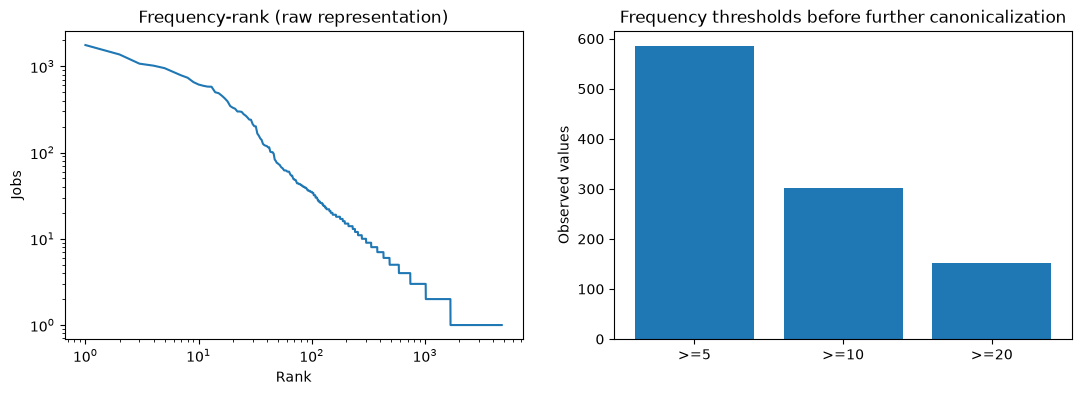

152-style count is representation-dependent; not a proof of impossibility after canonicalization: 152


In [3]:
rows=[set(map(str,a)) for a in df.skills_std]
counts=Counter(s for row in rows for s in row)
ordered=sorted(counts,key=lambda s:(-counts[s],s)); freq=np.array([counts[s] for s in ordered]); n=len(df)
lengths=np.array([len(s) for s in rows])
print('Jobs with any skill:',int((lengths>0).sum()),'/',n)
fig,ax=plt.subplots(1,2,figsize=(15,5))
ax[0].hist(lengths,bins=np.arange(lengths.max()+2)-.5);ax[0].set(xlabel='Distinct values/job (including 0)',ylabel='Jobs',title=f'Skill count per job; N={n}')
sns.barplot(x=freq[:30],y=ordered[:30],ax=ax[1]);ax[1].set(xlabel=f'Jobs containing value; denominator {n}',title='Top 30 observed values')
plt.tight_layout();plt.show()
fig,ax=plt.subplots(1,2,figsize=(13,4));ax[0].loglog(np.arange(1,len(freq)+1),freq);ax[0].set(xlabel='Rank',ylabel='Jobs',title='Frequency-rank (raw representation)')
ax[1].bar(['>=5','>=10','>=20'],[(freq>=k).sum() for k in [5,10,20]]);ax[1].set(ylabel='Observed values',title='Frequency thresholds before further canonicalization');plt.show()
print('152-style count is representation-dependent; not a proof of impossibility after canonicalization:',int((freq>=20).sum()))


## Coverage theo K
Các vocabulary raw top-K chưa được duyệt. Không trộn các tỷ lệ này với tỷ lệ sau alias mapping.

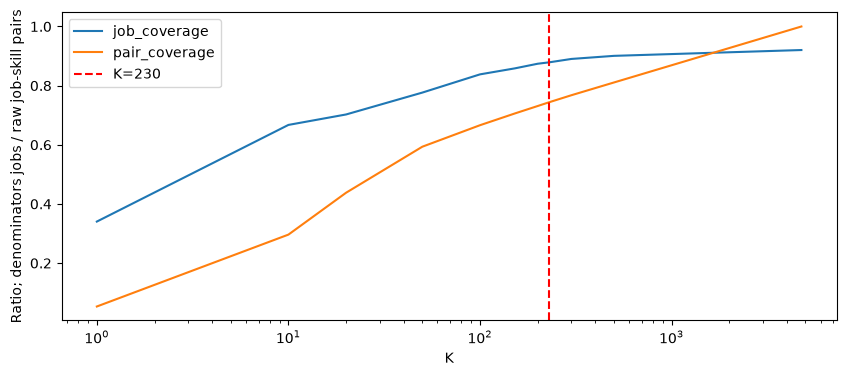

In [4]:
ks=sorted(set([1,10,20,50,100,152,200,230,300,500,len(ordered)]))
coverage=[]
for k in ks:
    v=set(ordered[:k]); coverage.append((k,sum(bool(s&v) for s in rows)/n,sum(counts[s] for s in v)/sum(counts.values())))
curve=pd.DataFrame(coverage,columns=['K','job_coverage','pair_coverage'])
curve.plot(x='K',y=['job_coverage','pair_coverage'],logx=True,figsize=(10,4));plt.axvline(230,color='red',ls='--',label='K=230');plt.ylabel('Ratio; denominators jobs / raw job-skill pairs');plt.legend();plt.show()


## Tỷ lệ theo nguồn
Mẫu số là số jobs của từng nguồn; chênh lệch có thể phản ánh phân khúc nguồn và quy tắc trích xuất.

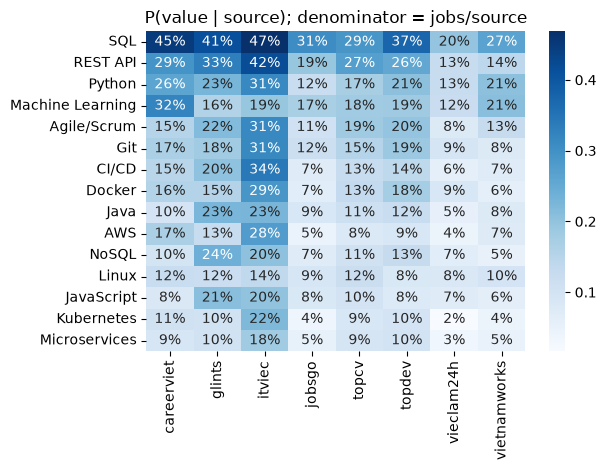

In [5]:
top=ordered[:15]; sources=sorted(df.source_platform.unique())
rates=pd.DataFrame({src:{s:sum(s in rows[i] for i in df.index[df.source_platform.eq(src)])/int(df.source_platform.eq(src).sum()) for s in top} for src in sources})
sns.heatmap(rates,annot=True,fmt='.0%',cmap='Blues');plt.title('P(value | source); denominator = jobs/source');plt.tight_layout();plt.show()


## Raw top230 và prototype hiện tại
Prototype scenario dùng đúng lookup tất định của code P5 (alias mơ hồ bị loại khỏi lookup). Cả hai scenario chưa approved.

,scenario,representation,job_coverage,pair_coverage,sparsity,zero_columns,jobs_denominator,pairs_denominator
0,raw,raw,0.878887,0.744025,0.979295,0,5177,33136
1,prototype_alias,prototype_alias,0.788294,0.605972,0.983211,81,5177,32990


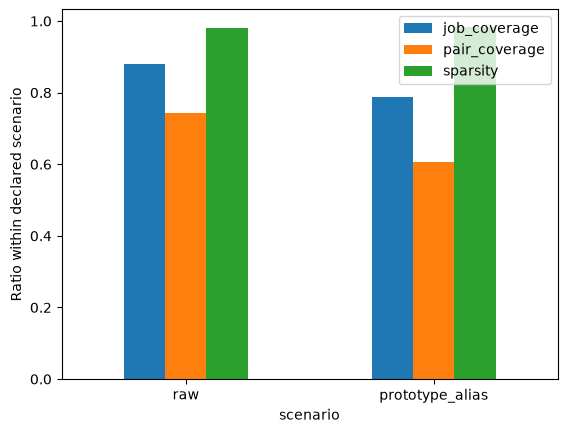

Alias conflicts: {'critical thinking': ['logical_thinking', 'problem_solving']}


In [6]:
prototype_rows=[]
for row in rows:
    prototype_rows.append({slug for s in row if (slug:=SKILL_LOOKUP_MAP.get(s.lower()) or SKILL_LOOKUP_MAP.get(to_col_slug(s)) or SKILL_LOOKUP_MAP.get(s))})
def metrics(label,data,vocab):
    c=Counter(s for row in data for s in row); kept=sum(c[s] for s in vocab)
    return dict(scenario=label,representation=label,job_coverage=sum(bool(row&vocab) for row in data)/n,pair_coverage=kept/sum(c.values()),sparsity=1-kept/(n*len(vocab)),zero_columns=sum(c[s]==0 for s in vocab),jobs_denominator=n,pairs_denominator=sum(c.values()))
# Prototype pair denominator also includes unmatched original values as distinct other tokens.
proto_data=[]
for raw,mapped in zip(rows,prototype_rows):
    unmatched={'OTHER:'+s for s in raw if not (SKILL_LOOKUP_MAP.get(s.lower()) or SKILL_LOOKUP_MAP.get(to_col_slug(s)) or SKILL_LOOKUP_MAP.get(s))}
    proto_data.append(mapped|unmatched)
comparison=pd.DataFrame([metrics('raw',rows,set(ordered[:230])),metrics('prototype_alias',proto_data,{s.slug for s in TAXONOMY_230})])
display(comparison);comparison.to_csv(OUT/'scenario_metrics.csv',index=False)
comparison.set_index('scenario')[['job_coverage','pair_coverage','sparsity']].plot.bar(rot=0);plt.ylabel('Ratio within declared scenario');plt.show()
print('Alias conflicts:',ALIAS_CONFLICTS)


## Sáu nhóm task — mapping đề xuất
Nhóm prototype mở rộng Security/QA/Data không phải schema nhóm đã duyệt. Crosswalk dưới đây chỉ là proposed; giữ phần chưa phân nhóm.

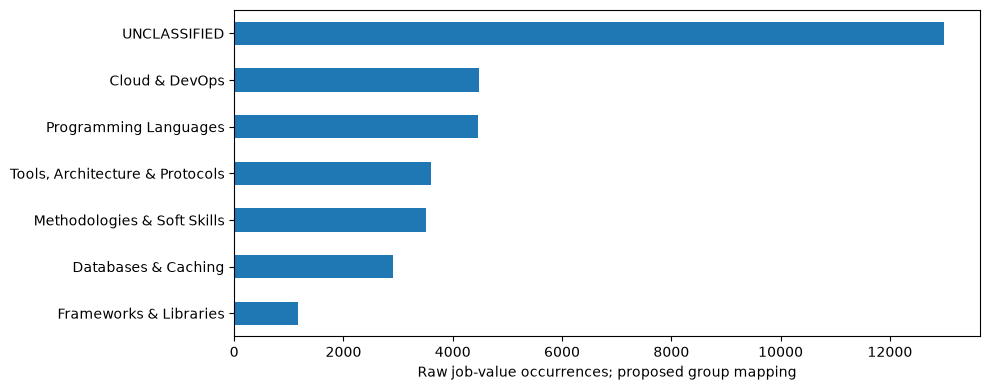

Group crosswalk is proposed. Manual decisions are never overwritten by this notebook.


In [7]:
group_map={'programming_languages':'Programming Languages','frameworks_libraries':'Frameworks & Libraries','databases_streaming':'Databases & Caching','cloud_devops_security':'Cloud & DevOps','tools_architecture_qa':'Tools, Architecture & Protocols','methodologies_softskills_data':'Methodologies & Soft Skills'}
slug_group={s.slug:group_map[s.group] for s in TAXONOMY_230}
group_counts=Counter()
for row in rows:
    for s in row:
        slug=SKILL_LOOKUP_MAP.get(s.lower()) or SKILL_LOOKUP_MAP.get(to_col_slug(s))
        group_counts[slug_group.get(slug,'UNCLASSIFIED')]+=1
pd.Series(group_counts).sort_values().plot.barh(figsize=(10,4));plt.xlabel('Raw job-value occurrences; proposed group mapping');plt.tight_layout();plt.show()
print('Group crosswalk is proposed. Manual decisions are never overwritten by this notebook.')


## Co-occurrence
C = XᵀX trên các giá trị raw phổ biến; đây là số jobs có cả hai giá trị, không phải quan hệ nhân quả.

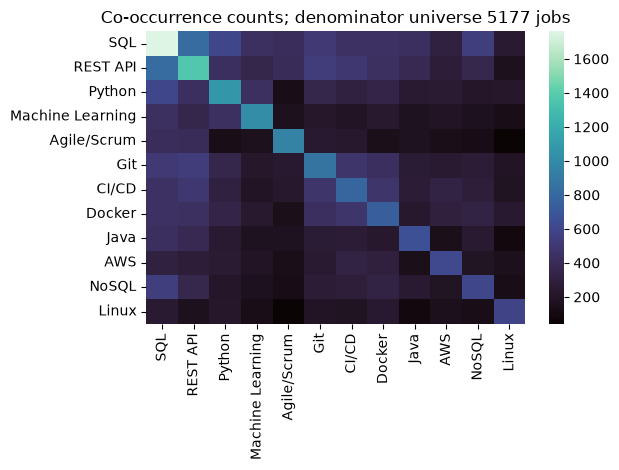

In [8]:
names=ordered[:12];X=np.array([[int(s in row) for s in names] for row in rows],dtype=np.int64)
C=X.T@X
assert np.array_equal(C,C.T) and np.array_equal(np.diag(C),X.sum(axis=0))
sns.heatmap(pd.DataFrame(C,index=names,columns=names),cmap='mako');plt.title(f'Co-occurrence counts; denominator universe {n} jobs');plt.tight_layout();plt.show()


## So sánh K — câu hỏi và phương pháp

**Câu hỏi:** tăng K quanh 230 giữ thêm bao nhiêu thông tin? **Cách tính:** frequency theo job, dedup sau mapping, tie-break tên tăng dần. Baseline giữ nguyên skills_std; canonical scenario chỉ chuẩn hóa hoa/thường theo tên canonical trong shared dictionary, không áp alias gộp công nghệ. Nhóm vẫn proposed.

**Kết quả:** bảng và đồ thị dưới đây được tính lại từ snapshot. **Giới hạn:** coverage đo sự giữ lại giá trị quan sát, không chứng minh chất lượng Mining hoặc K tối ưu. Không so pair coverage khác mẫu số như cùng một đại lượng.

,scenario,K,boundary_frequency,boundary_ties,selected,jobs_hit,jobs_denominator,job_coverage,pairs_kept,pairs_denominator,pair_coverage,sparsity,zero_columns,Programming Languages,Frameworks & Libraries,Databases & Caching,Cloud & DevOps,"Tools, Architecture & Protocols",Methodologies & Soft Skills,UNCLASSIFIED
0,baseline_skills_std,50,75,1,50,4020,5177,0.776511,19666,33136,0.593493,0.924025,0,12,5,2,5,2,3,21
1,baseline_skills_std,100,35,4,100,4339,5177,0.838130,22075,33136,0.666194,0.957359,0,13,5,3,6,3,7,63
2,baseline_skills_std,150,20,6,150,4440,5177,0.857640,23351,33136,0.704702,0.969930,0,14,5,3,10,6,8,104
3,baseline_skills_std,200,15,15,200,4525,5177,0.874058,24225,33136,0.731078,0.976603,0,14,6,3,12,7,11,147
4,baseline_skills_std,230,13,11,230,4550,5177,0.878887,24654,33136,0.744025,0.979295,0,14,6,3,13,7,11,176
5,baseline_skills_std,250,12,15,250,4568,5177,0.882364,24904,33136,0.751569,0.980758,0,14,6,3,14,8,11,194
6,baseline_skills_std,300,10,25,300,4609,5177,0.890284,25435,33136,0.767594,0.983623,0,14,6,3,15,8,11,243
7,baseline_skills_std,400,7,51,400,4639,5177,0.896079,26248,33136,0.792129,0.987325,0,15,7,4,16,8,12,338
8,baseline_skills_std,500,5,101,500,4663,5177,0.900715,26862,33136,0.810659,0.989623,0,16,8,4,18,10,14,430
9,canonical_spelling_only,50,75,1,50,4020,5177,0.776511,19666,33136,0.593493,0.924025,0,12,5,2,5,2,3,21


,scenario,threshold,selected,jobs_hit,jobs_denominator,job_coverage,pairs_kept,pairs_denominator,pair_coverage,sparsity,zero_columns
0,baseline_skills_std,5,586,4679,5177,0.903805,27292,33136,0.823636,0.991004,0
1,baseline_skills_std,10,301,4609,5177,0.890284,25445,33136,0.767896,0.983671,0
2,baseline_skills_std,20,152,4444,5177,0.858412,23391,33136,0.705909,0.970275,0
3,canonical_spelling_only,5,586,4679,5177,0.903805,27292,33136,0.823636,0.991004,0
4,canonical_spelling_only,10,301,4609,5177,0.890284,25445,33136,0.767896,0.983671,0
5,canonical_spelling_only,20,152,4444,5177,0.858412,23391,33136,0.705909,0.970275,0


,scenario,from_K,to_K,job_coverage_pp,pair_coverage_pp
0,baseline_skills_std,200,230,0.482905,1.294664
1,baseline_skills_std,230,250,0.347692,0.754466
2,baseline_skills_std,230,300,1.139656,2.356953
3,canonical_spelling_only,200,230,0.482905,1.294664
4,canonical_spelling_only,230,250,0.347692,0.754466
5,canonical_spelling_only,230,300,1.139656,2.356953


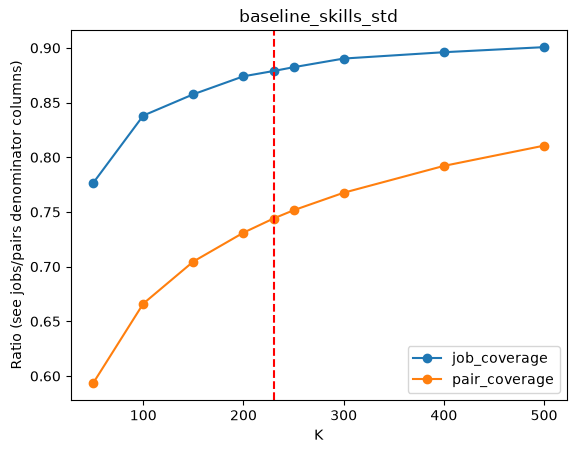

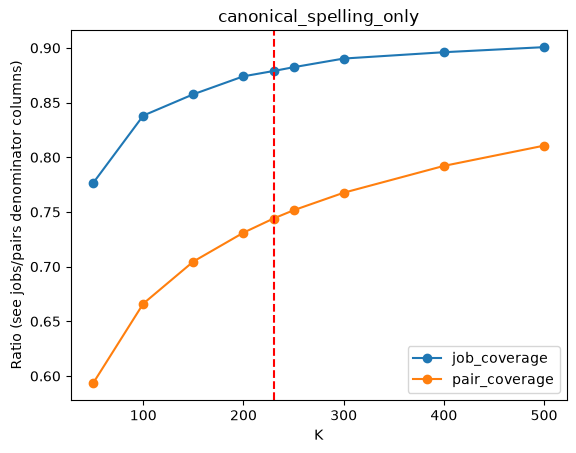

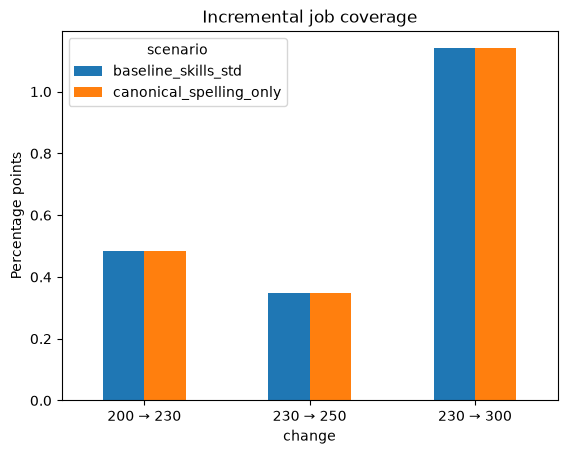

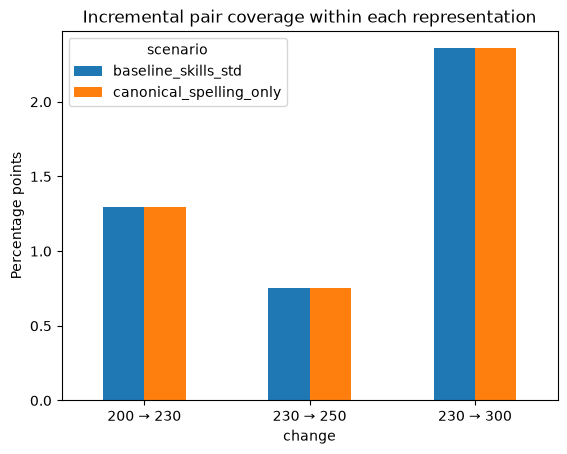

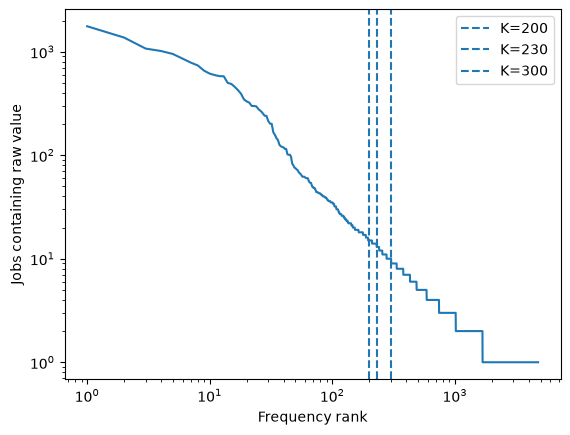

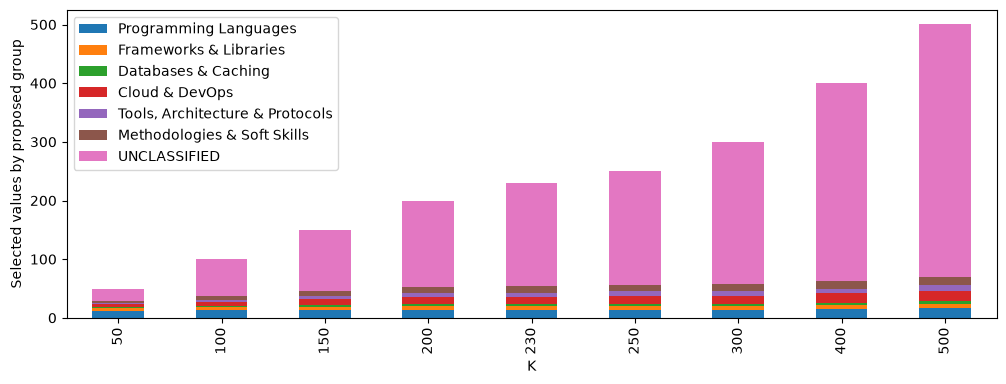

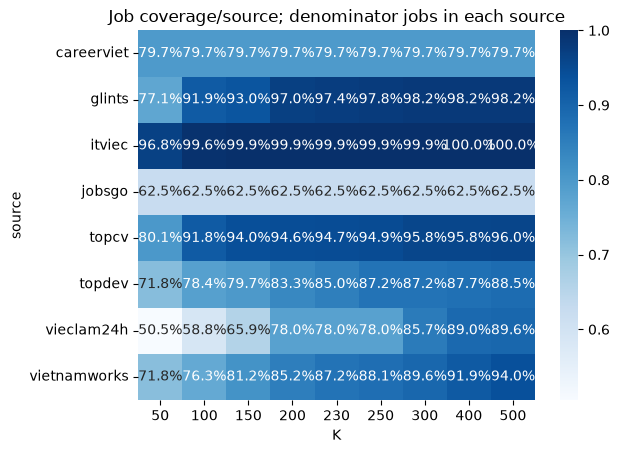

Raw K coverage is preliminary; 230 remains the approved task width, not an inferred optimal K.


In [9]:
from preprocessing.encoding.compare_vocabulary import generate
_,ktable,increments=generate(ROOT)
thresholds=pd.read_csv(OUT/'threshold_comparison.csv')
source_k=pd.read_csv(OUT/'k_source_coverage.csv')
display(ktable);display(thresholds);display(increments)
for scenario,g in ktable.groupby('scenario'):
    ax=g.plot(x='K',y=['job_coverage','pair_coverage'],marker='o',title=scenario)
    ax.axvline(230,color='red',ls='--');ax.set_ylabel('Ratio (see jobs/pairs denominator columns)');plt.show()
increments.assign(change=increments.from_K.astype(str)+' → '+increments.to_K.astype(str)).pivot(index='change',columns='scenario',values='job_coverage_pp').plot.bar(rot=0,title='Incremental job coverage');plt.ylabel('Percentage points');plt.show()
increments.assign(change=increments.from_K.astype(str)+' → '+increments.to_K.astype(str)).pivot(index='change',columns='scenario',values='pair_coverage_pp').plot.bar(rot=0,title='Incremental pair coverage within each representation');plt.ylabel('Percentage points');plt.show()
plt.loglog(np.arange(1,len(freq)+1),freq)
for k in [200,230,300]:plt.axvline(k,ls='--',label=f'K={k}')
plt.xlabel('Frequency rank');plt.ylabel('Jobs containing raw value');plt.legend();plt.show()
g=ktable[ktable.scenario.eq('baseline_skills_std')].set_index('K')
g[[*group_map.values(),'UNCLASSIFIED']].plot.bar(stacked=True,figsize=(12,4));plt.ylabel('Selected values by proposed group');plt.show()
s=source_k[source_k.scenario.eq('baseline_skills_std')].pivot(index='source',columns='K',values='job_coverage')
sns.heatmap(s,annot=True,fmt='.1%',cmap='Blues');plt.title('Job coverage/source; denominator jobs in each source');plt.show()
print('Raw K coverage is preliminary; 230 remains the approved task width, not an inferred optimal K.')


## Kết luận và quyết định

Các đồ thị chỉ mô tả snapshot ứng viên đã kiểm checksum. Frequency hiện tại phụ thuộc cách P3/P4 gộp alias; chưa chứng minh tính khả thi/bất khả thi sau canonicalization khác. Chưa xác minh mọi tag là skill chuẩn.

Phát cần quyết định snapshot chính thức, chính sách anomalies/missing, alias collision, danh sách 230 và threshold/tie/version, sáu nhóm, feature mapping, schema C, TF-IDF và Golden. Bảng CSV có cột accept/reject/edit; chưa có đề xuất mới được đánh dấu approved. Không có output production được ghi.